<a href="https://colab.research.google.com/github/8t6fut/smart-parking-prediction/blob/main/phase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully!
Number of records: 35717
  SystemCodeNumber  Capacity  Occupancy          LastUpdated
0      BHMBCCMKT01       577         61  2016-10-04 07:59:42
1      BHMBCCMKT01       577         64  2016-10-04 08:25:42
2      BHMBCCMKT01       577         80  2016-10-04 08:59:42
3      BHMBCCMKT01       577        107  2016-10-04 09:32:46
4      BHMBCCMKT01       577        150  2016-10-04 09:59:48

MODEL RESULTS
-------------------------
MAE: 439.38 occupied spaces
RMSE: 617.47 occupied spaces
R²: 0.442

PARKING AVAILABILITY PREDICTIONS
   Actual Occupancy  Predicted Occupancy  Available Spaces
0              2369              2042.97           2632.03
1              2485              2068.19           2606.81
2              2517              2085.10           2589.90
3              2539              2110.32           2564.68
4              2481              2135.54           2539.46
5              2390              2152.46           2522.54
6              2211      

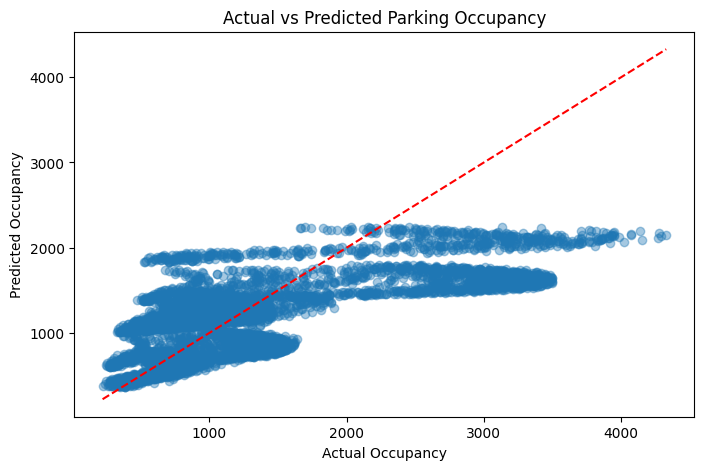


Experiment completed successfully!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import zipfile
import io

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00482/dataset.zip"

response = requests.get(url)
zip_file = zipfile.ZipFile(io.BytesIO(response.content))

csv_file = [f for f in zip_file.namelist() if f.endswith(".csv")][0]

df = pd.read_csv(zip_file.open(csv_file))

print("Dataset loaded successfully!")
print("Number of records:", len(df))
print(df.head())

# data preparation
df["LastUpdated"] = pd.to_datetime(df["LastUpdated"])

df["Hour"] = df["LastUpdated"].dt.hour
df["Minute"] = df["LastUpdated"].dt.minute
df["Day"] = df["LastUpdated"].dt.dayofweek

df = df.dropna()

# input features and target
X = df[["SystemCodeNumber", "Capacity", "Hour", "Minute", "Day"]]
y = df["Occupancy"]


split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# linear regression model
preprocessor = ColumnTransformer(
    transformers=[
        ("parking", OneHotEncoder(handle_unknown="ignore"),
         ["SystemCodeNumber"])
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

# make predictions
y_pred = model.predict(X_test)

# evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nMODEL RESULTS")
print("-------------------------")
print("MAE:", round(mae, 2), "occupied spaces")
print("RMSE:", round(rmse, 2), "occupied spaces")
print("R²:", round(r2, 3))

# available parking spaces
results = pd.DataFrame({
    "Actual Occupancy": y_test.values,
    "Predicted Occupancy": y_pred
})

results["Available Spaces"] = (
    df["Capacity"].iloc[split:].values
    - results["Predicted Occupancy"]
)

print("\nPARKING AVAILABILITY PREDICTIONS")
print(results.head(10).round(2))

# actual vs predicted graph
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual Occupancy")
plt.ylabel("Predicted Occupancy")
plt.title("Actual vs Predicted Parking Occupancy")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.show()

print("\nExperiment completed successfully!")